# BOBs Preprocessing — FOMO25

We preprocess the BOBs T2w images and BOBs9 segmentation masks to prepare them for FOMO25, using the same pipeline as for FeTA (`03_preprocess_feta.ipynb`).

The preprocessing functions are implemented in `src/preprocess.py`, while `scripts/preprocess.py` runs them on the full dataset.

Here, we go through the main steps, check the results, and make sure the MRI images and masks remain aligned.

1. Load the images and their corresponding segmentations as pairs
2. Reorient to RAS (right-anterior-superior)
3. Fill empty/NaN values by 0
4. Resample to a common spacing (1 mm isotropic)
5. Crop to the image & mask foreground (in some BOBs sessions, the mask labels voxels where the T2w is 0. up to 65 labelled voxels were lost before the crop fix)
6. Local padding (only if an image is smaller than the training patch)
7. Normalize intensities: per-volume Z-score
8. Check segmentation labels
9. Final preprocessing checks

PS: this pipeline follows the data transforms from https://github.com/Medical-Image-Analysis-Laboratory/segsynthtemplate/blob/main/configs/data/transforms/inference.yaml

## 1. Load images and their corresponding segmentations as pairs 

We first check that each BOBs T2w image has a matching BOBs9 segmentation mask. We expect 71 pairs in total (71 sessions from 51 infants).

Some infants were scanned more than once (e.g. at 2 and 8 months). Each session is treated as a separate scan.

In [1]:
from pathlib import Path 
import sys

PROJECT_ROOT = Path.cwd().parent 
sys.path.append(str(PROJECT_ROOT))

from src.preprocess import (find_image_label_pairs)

DATA_DIR = PROJECT_ROOT / "data" / "bobs" / "resampled75"
# BOBs has two segmentations per scan: we use the bobs9 one (not aseg)
pairs = find_image_label_pairs(DATA_DIR, seg_suffix="_desc-bobs9_dseg")

SPACING = (1.0, 1.0, 1.0)   # same as FeTA / FOMO25


print("Number of pairs: ", len(pairs))
print("First 5 pairs: ", pairs[:5])

Number of pairs:  71
First 5 pairs:  [(PosixPath('/Users/GwenBeulque/-brain-mri-foundation-models/data/bobs/resampled75/sub-116056/ses-3mo/anat/sub-116056_ses-3mo_space-INFANTMNIacpc_T2w.nii.gz'), PosixPath('/Users/GwenBeulque/-brain-mri-foundation-models/data/bobs/resampled75/sub-116056/ses-3mo/anat/sub-116056_ses-3mo_space-INFANTMNIacpc_desc-bobs9_dseg.nii.gz')), (PosixPath('/Users/GwenBeulque/-brain-mri-foundation-models/data/bobs/resampled75/sub-116845/ses-3mo/anat/sub-116845_ses-3mo_space-INFANTMNIacpc_T2w.nii.gz'), PosixPath('/Users/GwenBeulque/-brain-mri-foundation-models/data/bobs/resampled75/sub-116845/ses-3mo/anat/sub-116845_ses-3mo_space-INFANTMNIacpc_desc-bobs9_dseg.nii.gz')), (PosixPath('/Users/GwenBeulque/-brain-mri-foundation-models/data/bobs/resampled75/sub-116845/ses-6mo/anat/sub-116845_ses-6mo_space-INFANTMNIacpc_T2w.nii.gz'), PosixPath('/Users/GwenBeulque/-brain-mri-foundation-models/data/bobs/resampled75/sub-116845/ses-6mo/anat/sub-116845_ses-6mo_space-INFANTMNIacpc

## 2. Reorient to RAS

During EDA, all BOBs `resampled75` volumes were already in RAS. We still apply the reorientation, so that BOBs goes through exactly the same pipeline as FeTA.

This only rearranges the voxel axes; no interpolation is needed.

In [2]:
import nibabel as nib 

from src.preprocess import reorient_to_ras

n_not_ras = 0
for img_path, seg_path in pairs:
    if nib.aff2axcodes(nib.load(img_path).affine) != ("R", "A", "S"):
        n_not_ras += 1
    img = reorient_to_ras(nib.load(img_path))
    seg = reorient_to_ras(nib.load(seg_path))
    assert nib.aff2axcodes(img.affine) == ("R", "A", "S"), img_path.name
    assert nib.aff2axcodes(seg.affine) == ("R", "A", "S"), seg_path.name

print(n_not_ras, "pairs were not RAS before reorienting")
print("All", len(pairs), "pairs are RAS")

0 pairs were not RAS before reorienting
All 71 pairs are RAS


#### Visual check — RAS

We compare one MRI before and after reorientation, and overlay the segmentation to check that it follows the same transformation. If all scans were already RAS, both panels should look identical.

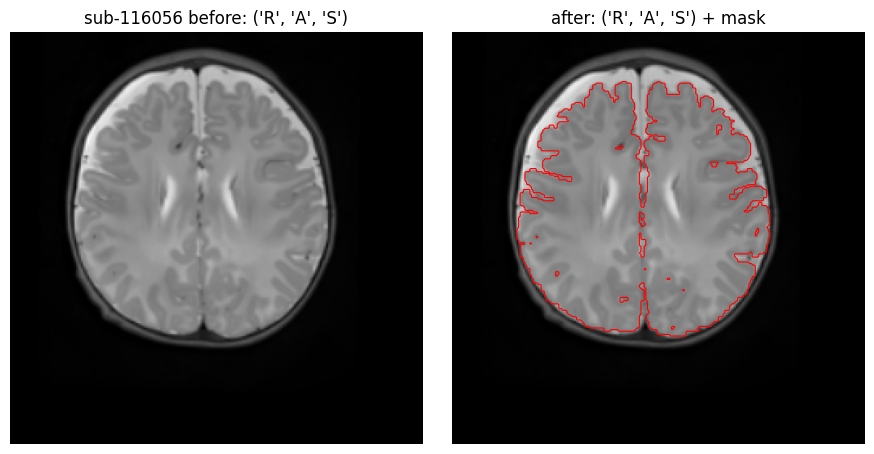

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Pick the first subject that was not RAS (if all were RAS already, just take the first one)
not_ras = [
    (i, s) for i, s in pairs
    if nib.aff2axcodes(nib.load(i).affine) != ("R", "A", "S")
]
img_path, seg_path = not_ras[0] if not_ras else pairs[0]

img_before = nib.load(img_path)
img_after = reorient_to_ras(img_before)
seg_after = reorient_to_ras(nib.load(seg_path))

before = img_before.get_fdata()
after = img_after.get_fdata()
mask = np.asarray(seg_after.dataobj)

z = after.shape[2] // 2   # middle axial slice

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))

axes[0].imshow(before[:, :, z].T, cmap="gray", origin="lower")
axes[0].set_title(f"{img_path.name.split('_')[0]} before: {nib.aff2axcodes(img_before.affine)}")

axes[1].imshow(after[:, :, z].T, cmap="gray", origin="lower")
axes[1].contour((mask[:, :, z] > 0).T, levels=[0.5], colors="red", linewidths=0.8)
axes[1].set_title(f"after: {nib.aff2axcodes(img_after.affine)} + mask")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

Reorienting RAS to RAS didn't change anything, which is what is wanted.

## 3. Fill empty/NaN values with 0

We already checked during EDA that none of the 71 BOBs T2w images contain NaN or Inf values. We still keep this step as a precaution, as for FeTA.

In [4]:
from src.preprocess import fill_nan

with_bad_values = 0

for img_path, seg_path in pairs:
    img = reorient_to_ras(nib.load(img_path))
    img_filled = fill_nan(img)

    before = img.get_fdata()
    after = img_filled.get_fdata()

    bad_before = np.isnan(before).sum() + np.isinf(before).sum()
    if bad_before > 0:
        with_bad_values += 1
        print(f"{img_path.name} has {bad_before} bad values before filling.")

    assert not np.isnan(after).any() and not np.isinf(after).any(), img_path.name
    assert nib.aff2axcodes(img_filled.affine) == ("R", "A", "S"), img_path.name

print(f"Done: {len(pairs)} images checked, {with_bad_values} had NaN/inf")

Done: 71 images checked, 0 had NaN/inf


## 4. Resampling to 1 mm isotropic spacing

BOBs `resampled75` volumes have 0.75 mm isotropic voxels. To match FeTA and FOMO25's preprocessing, we resample all images to 1 mm isotropic resolution (256³ at 0.75 mm becomes 193³ at 1 mm).

We use linear interpolation for the MRI and nearest-neighbor for the segmentation, so we don't introduce new label values.

In [5]:
from src.preprocess import resample_to_spacing

img_path, seg_path = pairs[0]
img = fill_nan(reorient_to_ras(nib.load(img_path)))
seg = reorient_to_ras(nib.load(seg_path))
img_r, seg_r = resample_to_spacing(img, seg, spacing=SPACING)

print("Spacing before:", img.header.get_zooms()[:3], "after:", img_r.header.get_zooms()[:3])
print("Shape before:  ", img.shape, "after:", img_r.shape, "| mask:", seg_r.shape)
print("Labels before: ", np.unique(np.asarray(seg.dataobj)))
print("Labels after:  ", np.unique(np.asarray(seg_r.dataobj)))
print("Still RAS:", nib.aff2axcodes(img_r.affine))

Spacing before: (np.float32(0.75), np.float32(0.75), np.float32(0.75)) after: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
Shape before:   (256, 256, 256) after: (193, 193, 193) | mask: (193, 193, 193)
Labels before:  [0 2 3 5 6 7 8 9]
Labels after:   [0 2 3 5 6 7 8 9]
Still RAS: ('R', 'A', 'S')


Now resampled to 1 mm isotropic spacing. We also checked that the MRI and segmentation share the same grid and that the original segmentation labels are preserved.

## 5. Foreground cropping

We crop the images to remove unnecessary background around the brain. This reduces the volume size while keeping the relevant anatomy.

The crop box is the smallest box containing every voxel where the MRI is positive **or** the mask is labelled, plus a 5-voxel margin. Using the mask as well guarantees that no labelled voxel is ever cut off. The same crop is applied to the MRI and its segmentation mask.

Before: (193, 193, 193) After: (192, 182, 185) (192, 182, 185)


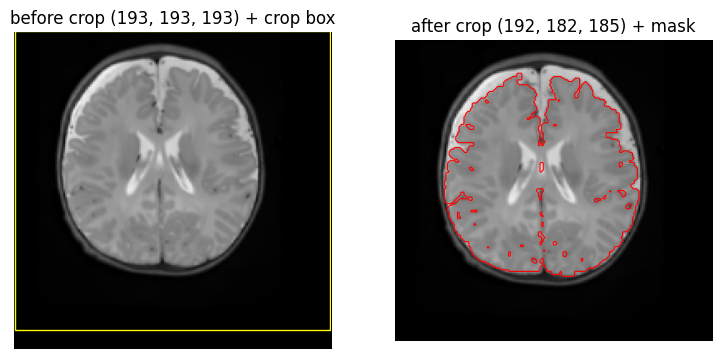

In [6]:
import matplotlib.patches as patches

from src.preprocess import crop_to_foreground

img_path, seg_path = pairs[0]
img = fill_nan(reorient_to_ras(nib.load(img_path)))
seg = reorient_to_ras(nib.load(seg_path))
img_r, seg_r = resample_to_spacing(img, seg, spacing=SPACING)
img_c, seg_c = crop_to_foreground(img_r, seg_r, margin=5)

print("Before:", img_r.shape, "After:", img_c.shape, seg_c.shape)

# Where the crop starts in the resampled volume (from the two affines),
# so both panels show the SAME slice
start = np.round(np.linalg.inv(img_r.affine) @ img_c.affine @ [0, 0, 0, 1])[:3].astype(int)
z_c = img_c.shape[2] // 2      # slice in the cropped volume
z = start[2] + z_c             # same slice in the uncropped volume

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(img_r.get_fdata()[:, :, z].T, cmap="gray", origin="lower")
axes[0].add_patch(patches.Rectangle(
    (start[0], start[1]), img_c.shape[0], img_c.shape[1],
    fill=False, edgecolor="yellow", linewidth=1,
))
axes[0].set_title(f"before crop {img_r.shape} + crop box")
axes[1].imshow(img_c.get_fdata()[:, :, z_c].T, cmap="gray", origin="lower")
axes[1].contour((np.asarray(seg_c.dataobj)[:, :, z_c] > 0).T, levels=[0.5], colors="red", linewidths=0.8)
axes[1].set_title(f"after crop {img_c.shape} + mask")
for ax in axes:
    ax.axis("off")
plt.show()

Cropping reduces the image size while keeping the MRI and segmentation on the same grid. The yellow box shows which part of the resampled volume is kept. We also check whether any labeled voxels touch the crop boundaries, which could indicate that the crop is too tight.

In [14]:
from src.preprocess import resample_and_crop

def labels_on_faces(mask):
    """Return which faces of the volume contain labelled voxels."""
    faces = {
        "x=0": mask[0, :, :],  "x=end": mask[-1, :, :],
        "y=0": mask[:, 0, :],  "y=end": mask[:, -1, :],
        "z=0": mask[:, :, 0],  "z=end": mask[:, :, -1],
    }
    return [name for name, face in faces.items() if np.any(face > 0)]

touching = []
for img_path, seg_path in pairs:
    img_c, seg_c = resample_and_crop(img_path, seg_path, spacing=(1, 1, 1), margin=5)
    faces = labels_on_faces(np.asarray(seg_c.dataobj))
    if faces:
        touching.append((img_path.name, faces))
        print(f"{img_path.name}: labels touch {faces}")

print(f"\nSubjects with labels on the crop boundary: {len(touching)}/{len(pairs)}")

sub-470437_ses-1mo_space-INFANTMNIacpc_T2w.nii.gz: labels touch ['y=0']

Subjects with labels on the crop boundary: 1/71


labelled voxels on the y=0 face  original: 8 | cropped: 5


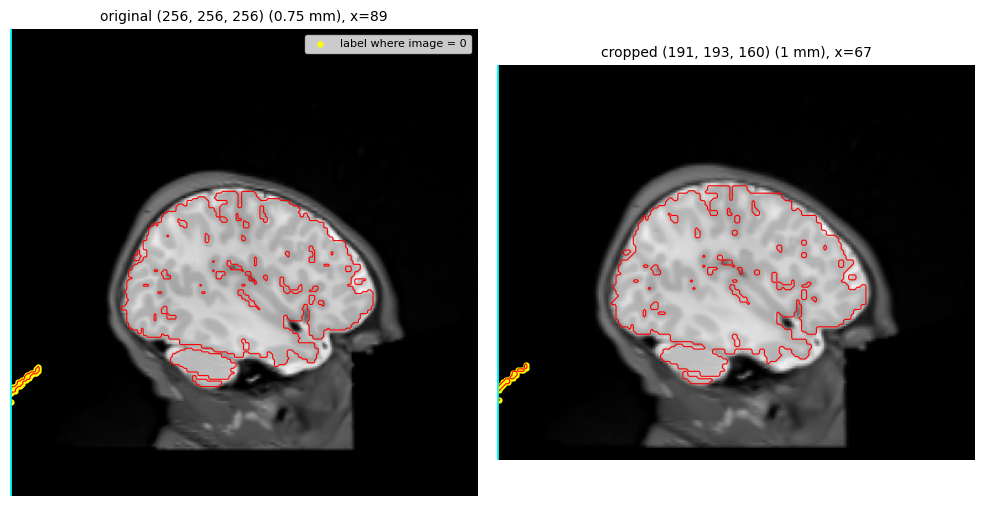

In [15]:
# sub-470437_ses-1mo: labels touch y=0 (back of the head). Original vs cropped.
img_path, seg_path = next((i, s) for i, s in pairs if i.name.startswith("sub-470437_ses-1mo"))

img = fill_nan(reorient_to_ras(nib.load(img_path)))
seg = reorient_to_ras(nib.load(seg_path))
img_r, seg_r = resample_to_spacing(img, seg, spacing=SPACING)
img_c, seg_c = crop_to_foreground(img_r, seg_r, margin=5)

# In each volume, pick the sagittal slice (fixed x) with the most labels on the y=0 face
mask_o = np.asarray(seg.dataobj) > 0
mask_c = np.asarray(seg_c.dataobj) > 0
x_o = mask_o[:, 0, :].sum(axis=1).argmax()
x_c = mask_c[:, 0, :].sum(axis=1).argmax()
print("labelled voxels on the y=0 face  original:", mask_o[:, 0, :].sum(), "| cropped:", mask_c[:, 0, :].sum())

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, im, m, x, title in [
    (axes[0], img, mask_o, x_o, f"original {img.shape} (0.75 mm), x={x_o}"),
    (axes[1], img_c, mask_c, x_c, f"cropped {img_c.shape} (1 mm), x={x_c}"),
]:
    data = im.get_fdata(dtype=np.float32)[x]       # sagittal slice: (y, z)
    ax.imshow(data.T, cmap="gray", origin="lower")
    ax.contour(m[x].T, levels=[0.5], colors="red", linewidths=0.8)
    yy, zz = np.nonzero(m[x] & (data == 0))         # labels where the image is 0
    ax.scatter(yy, zz, s=12, c="yellow", label="label where image = 0")
    ax.axvline(-0.5, color="cyan", lw=2)            # y=0 edge = back of the head
    ax.set_title(title, fontsize=10)
    ax.axis("off")
axes[0].legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()


A few BOBs masks contain isolated label voxels outside the head, in background where the T2w intensity is 0 (8–155 voxels per session, ≤ 0.04% of the labelled voxels). When the crop box was computed from the image only, these voxels were cut off in 5 sessions (2–65 voxels each), and 6/71 sessions had labels on the crop boundary. The crop box now uses the union of the image and the mask, so no labelled voxel is removed. We keep these voxels unchanged, since removing them would modify the reference segmentations (question sent to the supervisors).

The only session still touching the crop boundary is sub-470437_ses-1mo: 8 labelled voxels lie on the y=0 face (back of the head) of the original volume. The image only starts at y=15 at 1 mm, so these are stray labels on a zero-intensity background, not brain cut off by the field of view.

The cost of the union crop is that stray voxels far from the brain enlarge the crop box: for example, sub-116056_ses-3mo is now 192 voxels wide in x instead of 168.

## 6. Local padding

As for FeTA, we plan to train on fixed-size 3D patches (e.g., 96 × 96 × 96). Padding will only be added locally if an image is too small for the selected patch size.

This avoids storing unnecessarily large volumes and helps reduce GPU memory usage during training. Here we just look at the cropped shapes.

In [16]:
shapes = []
for img_path, seg_path in pairs:
    img = fill_nan(reorient_to_ras(nib.load(img_path)))
    seg = reorient_to_ras(nib.load(seg_path))
    img, seg = resample_to_spacing(img, seg, spacing=SPACING)
    img, seg = crop_to_foreground(img, seg, margin=5)
    shapes.append(img.shape)

shapes = np.array(shapes)
print("min shape per axis:", shapes.min(axis=0))
print("max shape per axis:", shapes.max(axis=0))

min shape per axis: [140 171 160]
max shape per axis: [192 193 192]


The smallest BOBs volume (140 × 171 × 160 at 1 mm) is larger than a 96³ patch on every axis, so no padding is needed for BOBs. The images keep their cropped shapes, and the MRI and segmentation still have matching dimensions. We don't apply global padding; fixed-size patches will be extracted later during training.

## 7. Z-score intensity normalization

During EDA, we saw that BOBs intensities vary a lot between sessions (e.g. mean nonzero T2w intensity from about 9 to 48). As for FeTA, we normalize each image separately using Z-score normalization, as described in FOMO25.

We calculate the mean and standard deviation using only nonzero voxels, leaving the background at zero. Since each image is normalized independently, we don't use statistics from the validation or test sets to normalize the training images.

In [17]:
from src.preprocess import zscore_intensity

# Select the first and last session (different infants / ages).
for img_path, seg_path in [pairs[0], pairs[-1]]:
    img = fill_nan(reorient_to_ras(nib.load(img_path)))
    seg = reorient_to_ras(nib.load(seg_path))

    img, seg = resample_to_spacing(img, seg, spacing=SPACING)
    img, seg = crop_to_foreground(img, seg, margin=5)

    # Normalize the MRI, not the segmentation mask.
    img_norm = zscore_intensity(img)

    data = img_norm.get_fdata(dtype=np.float32)
    foreground = data != 0

    print(f"\n{img_path.name}")
    print("Foreground mean:", round(float(data[foreground].mean()), 4))
    print("Foreground std:", round(float(data[foreground].std()), 4))
    print("Background stays zero:", np.all(data[~foreground] == 0))
    print("Segmentation labels:", np.unique(np.asarray(seg.dataobj)))


sub-116056_ses-3mo_space-INFANTMNIacpc_T2w.nii.gz
Foreground mean: 0.0
Foreground std: 1.0
Background stays zero: True
Segmentation labels: [0 2 3 5 6 7 8 9]

sub-993015_ses-5mo_space-INFANTMNIacpc_T2w.nii.gz
Foreground mean: -0.0
Foreground std: 1.0
Background stays zero: True
Segmentation labels: [0 2 3 5 6 7 8 9]


Images have a foreground mean close to 0 and a standard deviation close to 1 after normalization. The segmentation labels are unchanged, since normalization is applied only to the MRI.

## 8. Segmentation labels

During EDA, every BOBs9 mask contained the same 8 label values: `0, 2, 3, 5, 6, 7, 8, 9` (0 = background). Their anatomical names are not confirmed yet.

Unlike FeTA, these labels are **not consecutive** (1 and 4 are missing). We don't remap them here: the mapping (and whether BOBs classes can be matched to FeTA classes) is still waiting for the lab's answer.

We just check that all the original classes are still present after preprocessing and that no unexpected labels were introduced.

The last check reads the processed files, so run the full preprocessing first (from the project root):

```bash
python scripts/preprocess.py --dataset bobs --out-dir data/processed/bobs_fomo
```

In [18]:
from src.preprocess import preprocess_subject

expected_labels = {0, 2, 3, 5, 6, 7, 8, 9}
changed_subjects = []

for img_path, seg_path in pairs:
    original_mask = np.asarray(nib.load(seg_path).dataobj)
    _, processed_seg = preprocess_subject(
        img_path, seg_path, target_shape=None, spacing=SPACING
    )
    processed_mask = np.asarray(processed_seg.dataobj)

    labels_before = set(np.unique(original_mask).astype(int))
    labels_after = set(np.unique(processed_mask).astype(int))

    if labels_before != labels_after:
        changed_subjects.append(img_path.name)

print(f"Subjects with changed label sets: {len(changed_subjects)}/{len(pairs)}")
print("All processed labels valid:", all(
    set(np.unique(np.asarray(
        nib.load(
            (PROJECT_ROOT / "data" / "processed" / "bobs_fomo"
             / seg_path.relative_to(DATA_DIR))
        ).dataobj
    ))) <= expected_labels
    for _, seg_path in pairs
))

Subjects with changed label sets: 0/71
All processed labels valid: True


No session's label set changed during preprocessing, and all processed masks only contain the expected BOBs9 values. The labels are kept as they are until the mapping is confirmed.

## 9. Final preprocessing checks

We run the full preprocessing pipeline on all 71 BOBs sessions with the command from step 8.

To make sure everything worked correctly, we check the processed images and masks for spatial consistency, valid labels, and Z-score normalization.

The automated checks are implemented in `scripts/check_preprocessing.py` (with `--dataset bobs`).

In [19]:
import subprocess

# Run the automated quality-control checks on all 71 sessions.
result = subprocess.run(
    [sys.executable, str(PROJECT_ROOT / "scripts" / "check_preprocessing.py"), "--dataset", "bobs"],
    cwd=PROJECT_ROOT,
    capture_output=True,
    text=True,
)

# Show only the final summary.
print("\n".join(result.stdout.splitlines()[-5:]))

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Preprocessing quality control failed.")


--- Preprocessing quality control ---
Total subjects: 71
Passed: 71
Failed: 0


All 71 BOBs sessions (51 infants) passed the automated preprocessing checks.

The processed images have RAS orientation, 1 mm isotropic spacing, finite intensities, and foreground Z-score normalization. MRI and segmentation masks share the same shape and affine, with no unexpected label values.

We also visually checked MRI–mask overlays on example subjects. These checks are reassuring, although they don't fully rule out small anatomical errors introduced by resampling or cropping.